Libraries imported successfully!
Grid Size: 4 x 4
Start State: (0, 0)
Goal State: (3, 3)
Number of Actions: 4
Number of States: 16

State (0, 0) Index: 0
State (3, 3) Index: 15


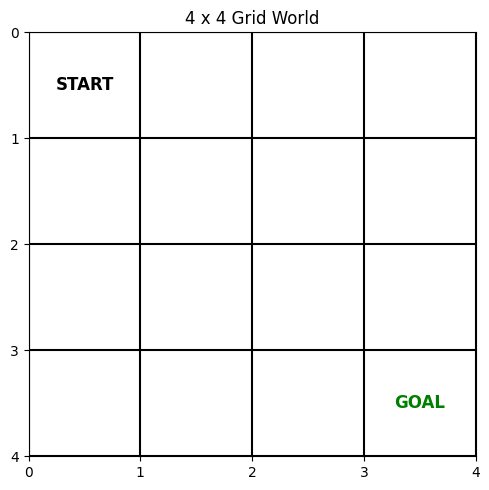

Learning Rate (alpha): 0.1
Discount Factor (gamma): 0.9
Episodes: 1000

Training completed!

Final Learned Q-Table:


,UP,DOWN,LEFT,RIGHT
0,0.3271,1.8098,0.3828,1.2497
1,-0.7280,3.0885,-1.2442,-0.4768
2,-0.4957,4.2278,-0.6798,-0.7224
3,-0.3940,2.1466,-0.4191,-0.3940
4,0.3082,1.7485,1.7146,3.1220
5,1.3287,3.8191,1.6594,4.5800
6,1.9112,6.2000,2.9298,5.1293
7,-0.2174,7.9790,0.3599,0.5264
8,-0.6581,-0.7595,-0.6793,4.1216
9,0.3105,-0.2293,-0.1938,6.1959



Learned Optimal Policy Grid:
[['S' '↓' '↓' '↓']
 ['→' '→' '↓' '↓']
 ['→' '→' '→' '↓']
 ['→' '→' '→' 'G']]


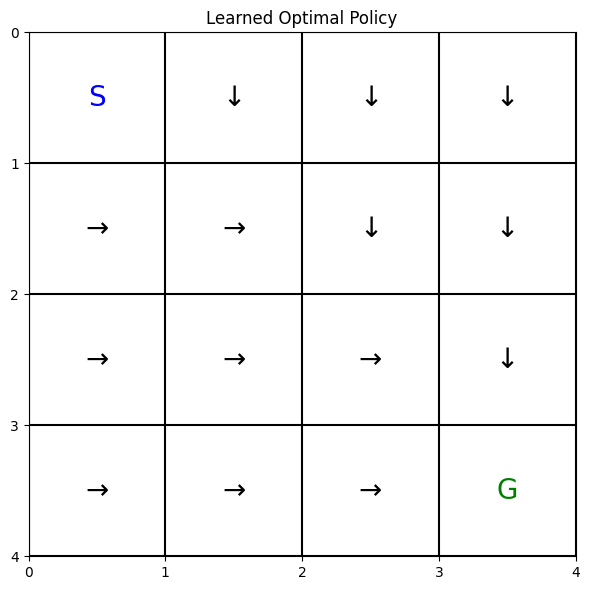

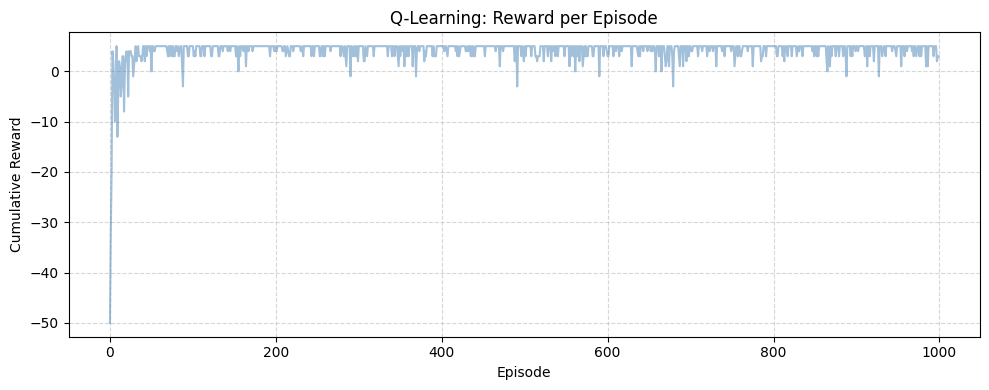

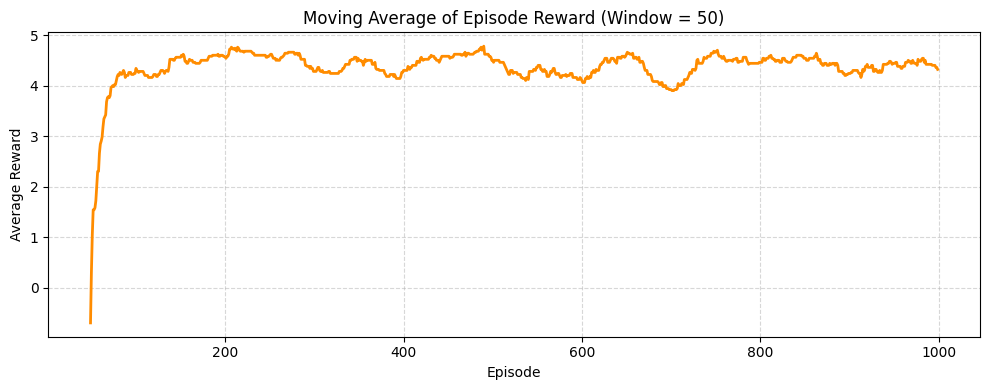


--- Summary Performance Metrics (epsilon = 0.1) ---
Success Rate   : 100.00%
Average Reward : 4.15
Average Steps  : 6.85

--- Effect of Epsilon Comparison ---


,Epsilon,Average Reward,Success Rate (%),Average Steps
0,0.50,-0.496,100.0,11.496
1,0.10,4.121,100.0,6.879
2,0.01,4.651,100.0,6.349


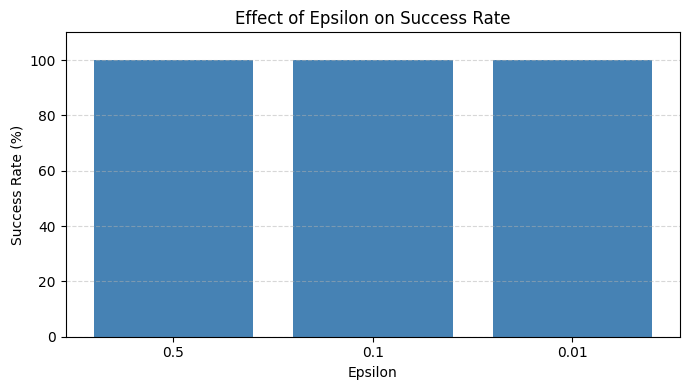

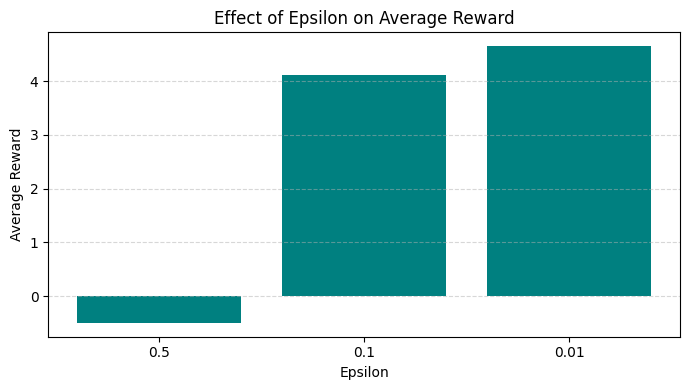

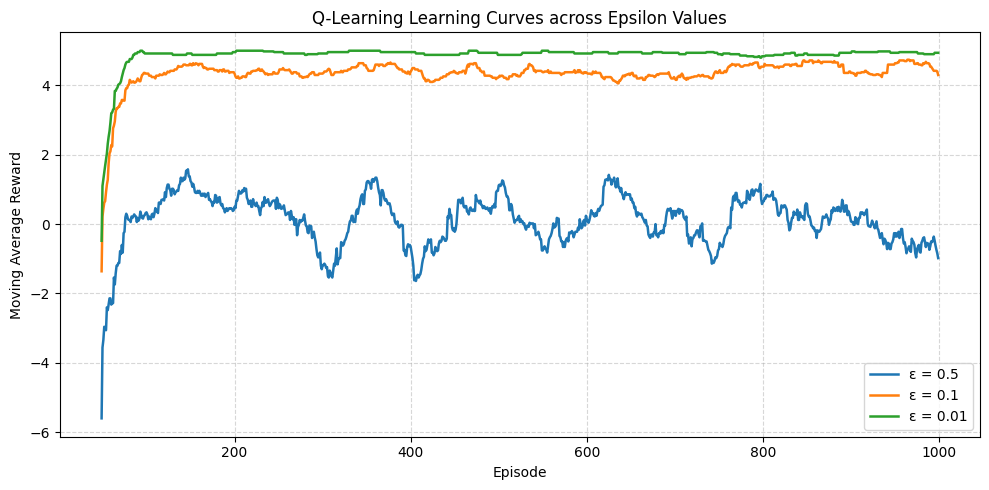

In [1]:
# ============================================================
# REINFORCEMENT LEARNING: Q-LEARNING ON 4x4 GRID WORLD
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

print("Libraries imported successfully!")

# --- Step 1: Environment Definition ---
GRID_SIZE = 4
START_STATE = (0, 0)
GOAL_STATE = (3, 3)

UP = 0
DOWN = 1
LEFT = 2
RIGHT = 3
actions = [UP, DOWN, LEFT, RIGHT]
NUM_ACTIONS = len(actions)
NUM_STATES = GRID_SIZE * GRID_SIZE

print("Grid Size:", GRID_SIZE, "x", GRID_SIZE)
print("Start State:", START_STATE)
print("Goal State:", GOAL_STATE)
print("Number of Actions:", NUM_ACTIONS)
print("Number of States:", NUM_STATES)


def state_to_number(state):
    row, col = state
    return row * GRID_SIZE + col


def number_to_state(state_number):
    row = state_number // GRID_SIZE
    col = state_number % GRID_SIZE
    return (row, col)


print("\nState (0, 0) Index:", state_to_number((0, 0)))
print("State (3, 3) Index:", state_to_number((3, 3)))


def take_action(state, action):
    row, col = state

    if action == UP:
        new_row, new_col = row - 1, col
    elif action == DOWN:
        new_row, new_col = row + 1, col
    elif action == LEFT:
        new_row, new_col = row, col - 1
    elif action == RIGHT:
        new_row, new_col = row, col + 1

    # Check grid boundaries
    if new_row < 0 or new_row >= GRID_SIZE or new_col < 0 or new_col >= GRID_SIZE:
        next_state = state  # Invalid move: bounce back to same position
    else:
        next_state = (new_row, new_col)

    # Check goal reward
    if next_state == GOAL_STATE:
        reward = 10
        done = True
    else:
        reward = -1
        done = False

    return next_state, reward, done


# Visualizing initial environment setup
plt.figure(figsize=(5, 5))
for i in range(GRID_SIZE + 1):
    plt.axhline(i, color="black")
    plt.axvline(i, color="black")

plt.text(0.5, 0.5, "START", ha="center", va="center", fontsize=12, fontweight="bold")
plt.text(3.5, 3.5, "GOAL", ha="center", va="center", fontsize=12, fontweight="bold", color="green")
plt.xlim(0, GRID_SIZE)
plt.ylim(0, GRID_SIZE)
plt.xticks(range(GRID_SIZE + 1))
plt.yticks(range(GRID_SIZE + 1))
plt.gca().invert_yaxis()
plt.title("4 x 4 Grid World")
plt.tight_layout()
plt.show()

# --- Step 2: Q-Learning Training Algorithm ---
alpha = 0.1      # Learning Rate
gamma = 0.9      # Discount Factor
episodes = 1000
max_steps = 100

print(f"Learning Rate (alpha): {alpha}")
print(f"Discount Factor (gamma): {gamma}")
print(f"Episodes: {episodes}")


def train_q_learning(epsilon):
    Q_table = np.zeros((NUM_STATES, NUM_ACTIONS))
    rewards = []
    steps_list = []
    success_list = []

    for episode in range(episodes):
        state = START_STATE
        total_reward = 0
        success = 0

        for step in range(max_steps):
            state_number = state_to_number(state)

            # Epsilon-greedy action selection
            if np.random.random() < epsilon:
                action = np.random.randint(NUM_ACTIONS)  # Exploration
            else:
                action = np.argmax(Q_table[state_number])  # Exploitation

            next_state, reward, done = take_action(state, action)
            next_state_number = state_to_number(next_state)

            # Bellman Equation Update
            best_next_value = np.max(Q_table[next_state_number])
            Q_table[state_number, action] += alpha * (
                reward + gamma * best_next_value - Q_table[state_number, action]
            )

            state = next_state
            total_reward += reward

            if done:
                success = 1
                break

        rewards.append(total_reward)
        steps_list.append(step + 1)
        success_list.append(success)

    return Q_table, rewards, steps_list, success_list


# Train baseline model with epsilon = 0.1
Q_01, rewards_01, steps_01, success_01 = train_q_learning(epsilon=0.1)
print("\nTraining completed!")

# --- Step 3: Inspect Learned Q-Table ---
print("\nFinal Learned Q-Table:")
q_df = pd.DataFrame(Q_01, columns=["UP", "DOWN", "LEFT", "RIGHT"])
display(q_df.round(4))

# --- Step 4: Extract and Visualize Optimal Policy ---
action_symbols = {UP: "↑", DOWN: "↓", LEFT: "←", RIGHT: "→"}

policy = []
for state_number in range(NUM_STATES):
    best_action = np.argmax(Q_01[state_number])
    policy.append(action_symbols[best_action])

policy_grid = np.array(policy).reshape(GRID_SIZE, GRID_SIZE)
policy_grid[0, 0] = "S"
policy_grid[3, 3] = "G"

print("\nLearned Optimal Policy Grid:")
print(policy_grid)

plt.figure(figsize=(6, 6))
for i in range(GRID_SIZE + 1):
    plt.axhline(i, color="black")
    plt.axvline(i, color="black")

for row in range(GRID_SIZE):
    for col in range(GRID_SIZE):
        text = policy_grid[row, col]
        color = "green" if text == "G" else ("blue" if text == "S" else "black")
        plt.text(col + 0.5, row + 0.5, text, ha="center", va="center", fontsize=20, color=color)

plt.xlim(0, GRID_SIZE)
plt.ylim(0, GRID_SIZE)
plt.xticks(range(GRID_SIZE + 1))
plt.yticks(range(GRID_SIZE + 1))
plt.gca().invert_yaxis()
plt.title("Learned Optimal Policy")
plt.tight_layout()
plt.show()

# --- Step 5: Reward Convergence Curves ---
plt.figure(figsize=(10, 4))
plt.plot(rewards_01, alpha=0.5, color="steelblue")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")
plt.title("Q-Learning: Reward per Episode")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

window = 50
moving_average = pd.Series(rewards_01).rolling(window).mean()

plt.figure(figsize=(10, 4))
plt.plot(moving_average, color="darkorange", linewidth=2)
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.title("Moving Average of Episode Reward (Window = 50)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Compute summary performance metrics
success_rate = np.mean(success_01) * 100
successful_steps = [steps_01[i] for i in range(len(steps_01)) if success_01[i] == 1]
average_steps = np.mean(successful_steps) if successful_steps else np.nan
average_reward = np.mean(rewards_01)

print("\n--- Summary Performance Metrics (epsilon = 0.1) ---")
print(f"Success Rate   : {success_rate:.2f}%")
print(f"Average Reward : {average_reward:.2f}")
print(f"Average Steps  : {average_steps:.2f}")

# --- Step 6: Parameter Experiment (Effect of Epsilon) ---
epsilon_values = [0.5, 0.1, 0.01]
results = []

for eps in epsilon_values:
    Q_temp, rewards_temp, steps_temp, success_temp = train_q_learning(eps)
    s_rate = np.mean(success_temp) * 100
    avg_rew = np.mean(rewards_temp)
    s_steps = [steps_temp[i] for i in range(len(steps_temp)) if success_temp[i] == 1]
    avg_st = np.mean(s_steps) if s_steps else np.nan

    results.append([eps, avg_rew, s_rate, avg_st])

results_df = pd.DataFrame(
    results,
    columns=["Epsilon", "Average Reward", "Success Rate (%)", "Average Steps"],
)

print("\n--- Effect of Epsilon Comparison ---")
display(results_df.round(4))

# Bar chart: Success rate by epsilon
plt.figure(figsize=(7, 4))
plt.bar(results_df["Epsilon"].astype(str), results_df["Success Rate (%)"], color="steelblue")
plt.xlabel("Epsilon")
plt.ylabel("Success Rate (%)")
plt.title("Effect of Epsilon on Success Rate")
plt.ylim(0, 110)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Bar chart: Average reward by epsilon
plt.figure(figsize=(7, 4))
plt.bar(results_df["Epsilon"].astype(str), results_df["Average Reward"], color="teal")
plt.xlabel("Epsilon")
plt.ylabel("Average Reward")
plt.title("Effect of Epsilon on Average Reward")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Comparative learning curves
plt.figure(figsize=(10, 5))
for eps in epsilon_values:
    _, rewards_temp, _, _ = train_q_learning(eps)
    moving_avg = pd.Series(rewards_temp).rolling(50).mean()
    plt.plot(moving_avg, label=f"ε = {eps}", linewidth=1.8)

plt.xlabel("Episode")
plt.ylabel("Moving Average Reward")
plt.title("Q-Learning Learning Curves across Epsilon Values")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()